# A2：卷积网络

本 Notebook 展示各项实验结果。训练代码位于 `src/cifar10_lab/`。

完整解释见 [实验报告](REPORT.md)。运行方法见 [README](README.md)。

Notebook 的代码单元读取保存的实验结果。

## 题目要求与代码对应说明

代码文件均位于 `src/cifar10_lab/`。下面按题目顺序说明实验、代码和报告章节。

**基础题：构建图像分类网络。** `models.py` 的 `Classifier` 定义卷积网络，`ConvBlock` 定义卷积块。`experiment.py` 的 `train_run` 训练模型，`evaluate_all` 计算测试准确率。第 3 节介绍结构，第 5 节展示训练曲线和分类结果。

**基础题：应用 Dropout 和多种归一化方法。** `models.py` 的 `Classifier` 在分类层中使用 `nn.Dropout`，`normalization` 创建 4 种归一化层及对照配置。`experiment.py` 的 `final_specs` 设置对照模型。第 4 节比较 15 组配置；第 5.1 节比较 `selected` 与 `dropout_variant`，说明 Dropout 的影响，再比较 `dropout_variant` 与 `no_normalization`，说明归一化的影响。

**基础题：通过交叉验证选择超参数。** `experiment.py` 的 `cross_validate` 将 9000 张训练图像分成 3 折，对每组配置训练 3 次，再按平均验证准确率选择配置。第 4 节给出各组均值、标准差和选中的配置。

**附加题 1：尝试提高分类准确率的方法。** `experiment.py` 的 `final_specs` 设置加深网络、残差连接和 Cutout 实验；`evaluate_all` 将 3 个模型的预测概率取平均，得到集成预测。`data.py` 的 `batch_transform` 实现训练时的随机遮挡。第 5.2 节比较深度、残差连接和集成，第 7.2 节比较 Cutout。

**附加题 2：比较卷积核大小并展示图像特征。** `models.py` 的 `ConvBlock` 根据 `kernel_size` 创建卷积层，`experiment.py` 的 `final_specs` 设置 3×3、5×5、7×7 对照。`report.py` 的 `visual_features` 绘制卷积核权重、特征图和输入梯度图。第 6 节结合这些图，比较准确率、参数量、运行时间和图像特征。

**附加题 3：分析模型缺陷并提出改进方案。** `data.py` 的 `occlude` 遮挡测试图像中心，`experiment.py` 的 `predict` 计算两种图像条件下的预测。`report.py` 的 `plot_confusion` 和 `plot_errors` 展示分类错误。第 7 节分析训练与验证准确率差距、遮挡影响和类别混淆，并用 Cutout 实验验证改善遮挡表现的方法。延后下采样和保留高分辨率分支列为后续方案。

表格中的 `model` 表示模型名称，`clean` 表示完整图像准确率，`occluded` 表示中心遮挡图像准确率。中心遮挡覆盖 8×8 像素，填充值为中灰色。



In [1]:
from pathlib import Path
import json
import sys

ROOT = next(p for p in [Path.cwd(), Path.cwd() / "A2_cifar10", Path.cwd().parent]
            if (p / "configs" / "experiment.json").exists())
sys.path.insert(0, str(ROOT / "src"))
print(ROOT)

/Users/zhaozheyun/Code/GitHub/NNDL/A2_cifar10


## 实验配置

程序保存固定数据划分和实际依赖版本。程序按验证准确率选择最佳权重。

In [2]:
config = json.loads((ROOT / "configs" / "experiment.json").read_text())
print(json.dumps(config, indent=2, ensure_ascii=False))

{
  "seed": 42,
  "device": "auto",
  "threads": 4,
  "batch_size": 256,
  "epochs": 20,
  "learning_rate": 0.001,
  "weight_decay": 0.0005,
  "width": 32,
  "cv_samples": 9000,
  "cv_folds": 3,
  "cv_epochs": 3,
  "cv_batch_size": 256,
  "normalizations": [
    "none",
    "batch",
    "instance",
    "layer",
    "group"
  ],
  "dropout_rates": [
    0.0,
    0.2,
    0.5
  ],
  "ensemble_members": [
    "selected",
    "deep",
    "residual_cutout"
  ],
  "occlusion_size": 8
}


## 模型结构

模型支持 5 种归一化配置，以及 3 种卷积核大小。

In [3]:
from cifar10_lab.models import Classifier, ModelSpec, parameter_count
selection = json.loads((ROOT / "results" / "selection.json").read_text())["selected"]
spec = ModelSpec(normalization=selection["normalization"], dropout=selection["dropout"], width=config["width"])
model = Classifier(spec)
print(model)
print("Trainable parameters:", parameter_count(model))

Classifier(
  (blocks): ModuleList(
    (0): ConvBlock(
      (body): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (body): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ConvBlock(
      (body): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=

## 交叉验证

各组合使用相同的分层折划分。程序使用验证准确率选择超参数。

In [4]:
selection = json.loads((ROOT / "results" / "selection.json").read_text())
print(json.dumps(selection, indent=2, ensure_ascii=False))

{
  "criterion": "maximum mean of fold-best validation accuracies; grid order breaks ties",
  "selected": {
    "normalization": "batch",
    "dropout": 0.0,
    "fold_accuracies": [
      0.5306666666666666,
      0.498,
      0.5173333333333333
    ],
    "mean_accuracy": 0.5153333333333333,
    "std_accuracy": 0.01642491332633987
  },
  "cv_samples": 9000,
  "folds": 3,
  "epochs_per_fold": 3,
  "test_used": false
}


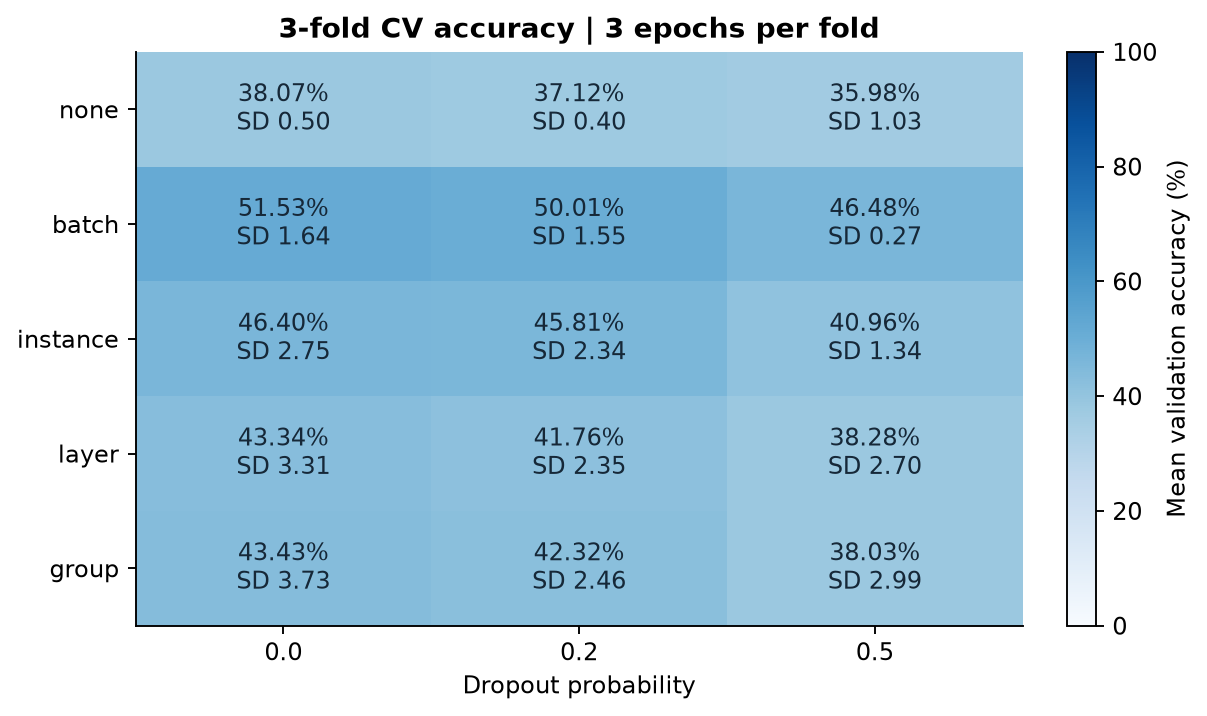

In [5]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "cross_validation.png")))

## 最终结果

以下输出来自保存的预测结果。准确率以百分比显示。

In [6]:
metrics = json.loads((ROOT / "results" / "test_metrics.json").read_text())
print("model（模型）            clean（完整图像）    occluded（中心遮挡）")
for name, row in metrics.items():
    print(f"{name:24s} {row['clean']['accuracy']*100:6.2f}%  {row['occluded']['accuracy']*100:6.2f}%")

model（模型）            clean（完整图像）    occluded（中心遮挡）
baseline                  76.93%   70.80%
selected                  81.33%   73.80%
dropout_variant           80.73%   72.65%
no_normalization          76.67%   70.34%
kernel5                   82.80%   74.96%
kernel7                   81.91%   74.23%
deep                      87.25%   76.65%
residual                  87.56%   76.81%
residual_cutout           87.06%   83.19%
ensemble                  88.08%   82.20%


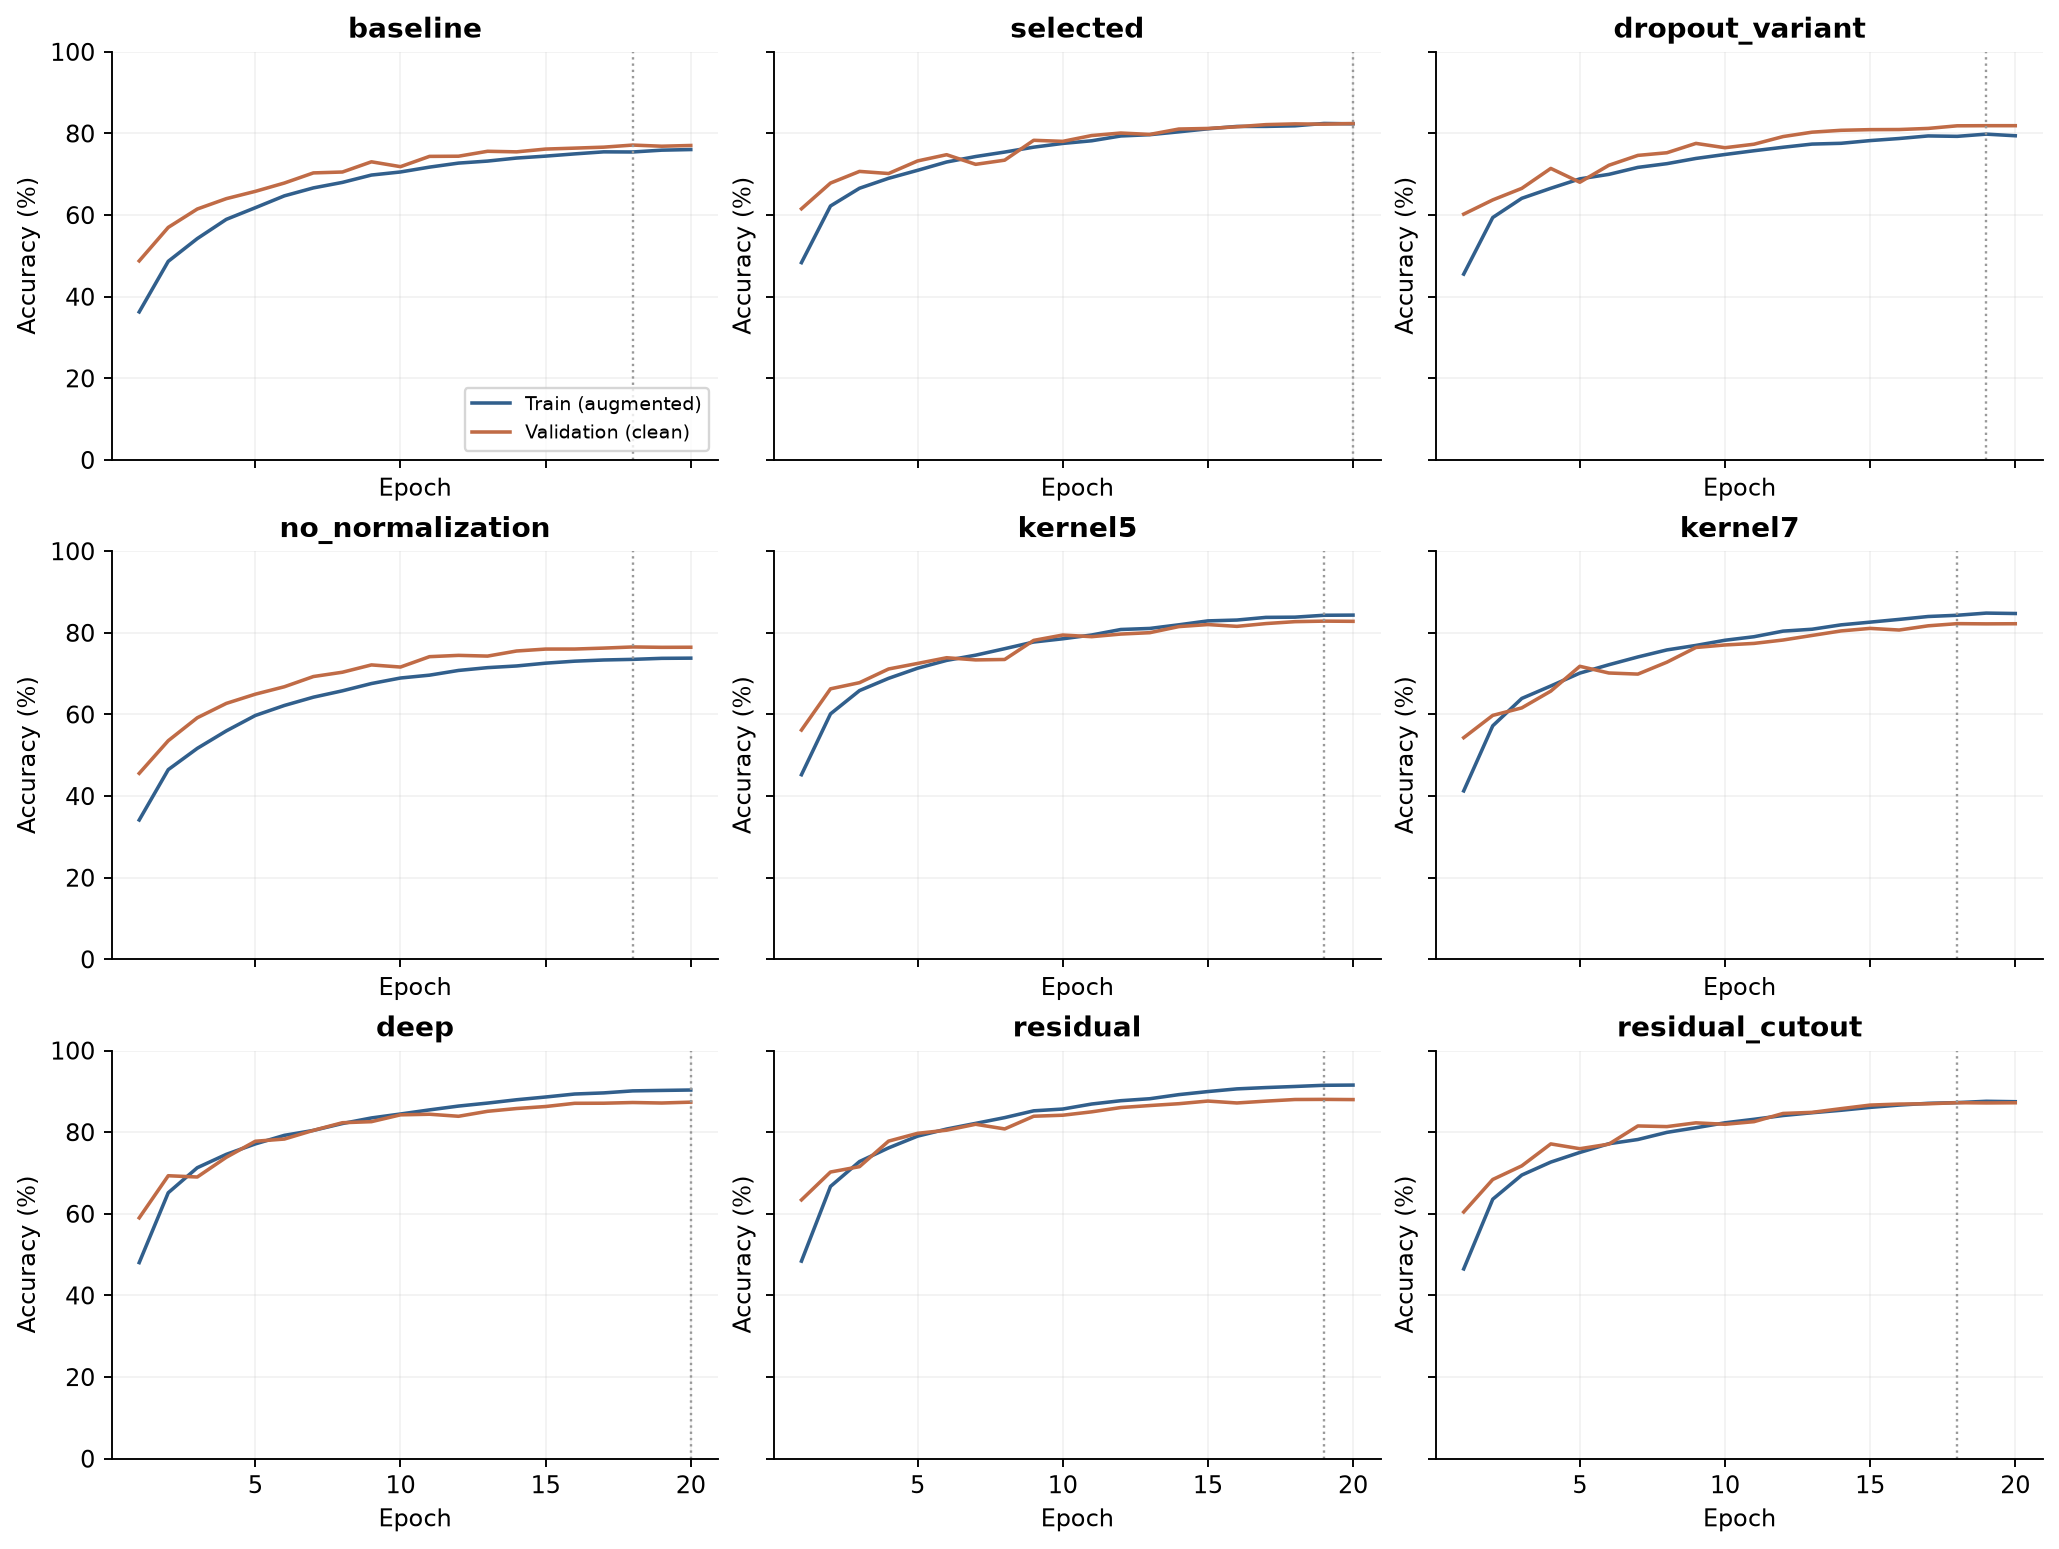

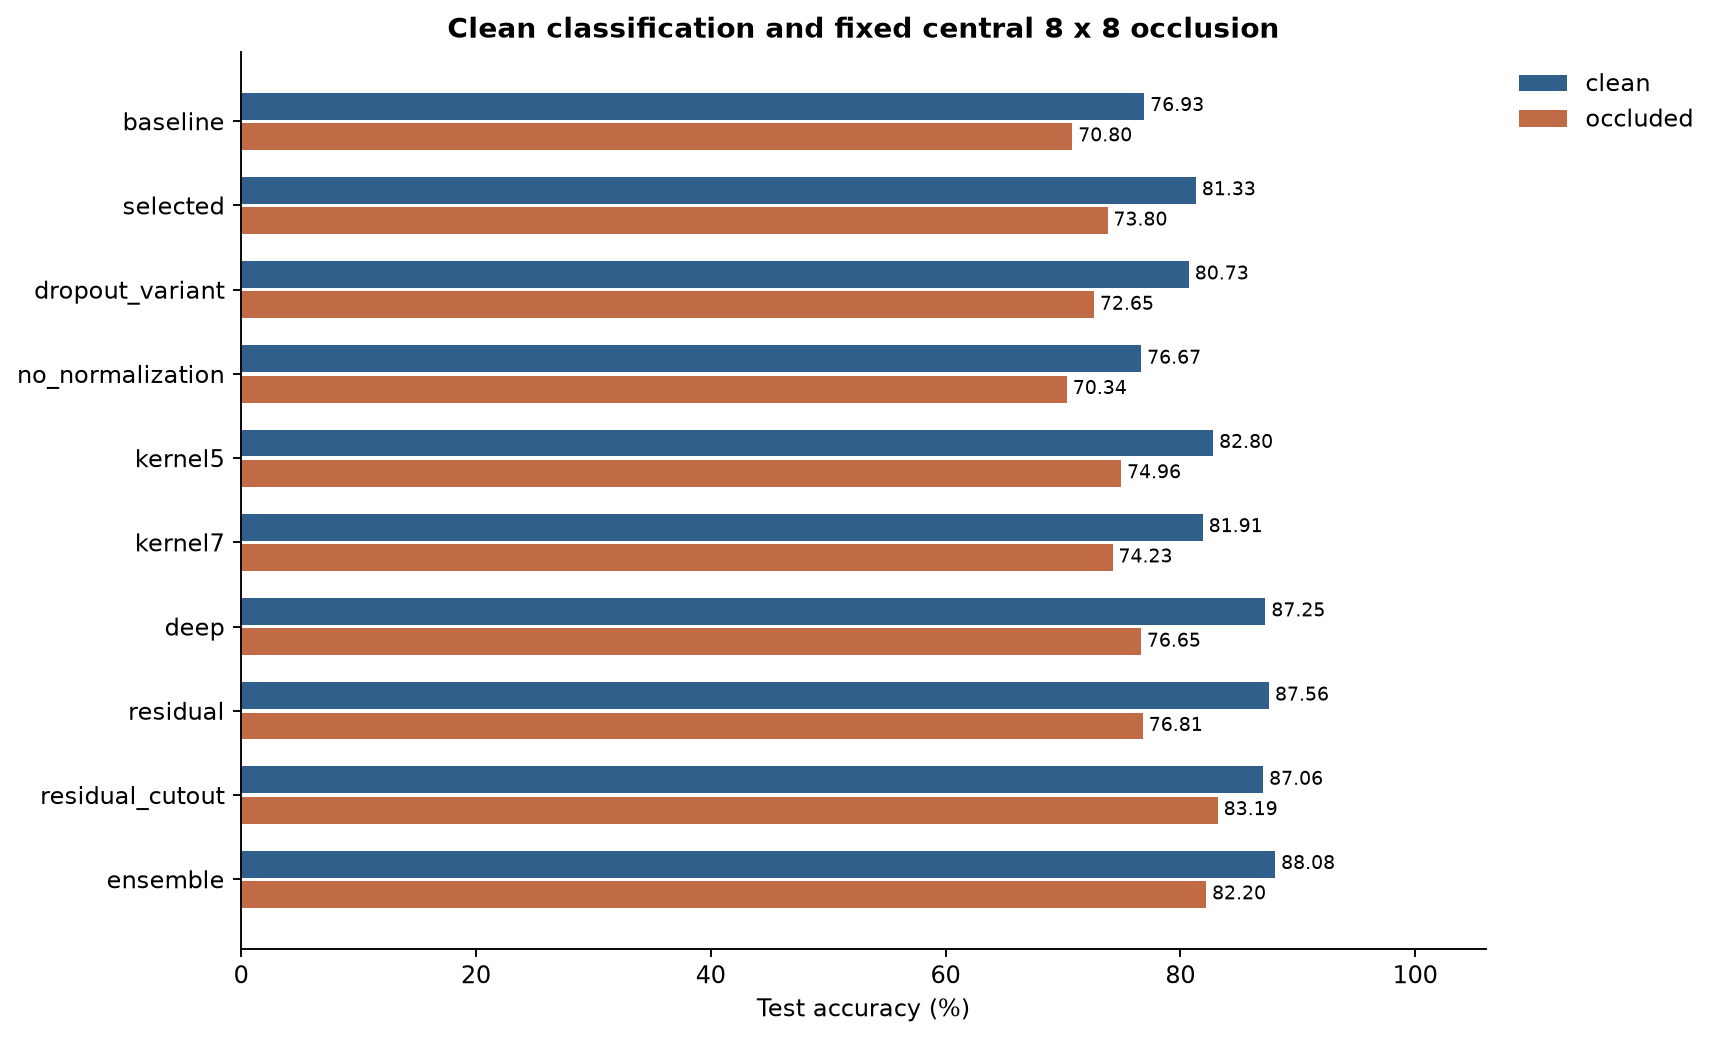

In [7]:
display(Image(filename=str(ROOT / "figures" / "learning_curves.png")))
display(Image(filename=str(ROOT / "figures" / "accuracy_comparison.png")))

## 卷积核与特征图

不同模型使用相同测试图像。每张热图分别缩放颜色，用于展示图像各位置的响应。

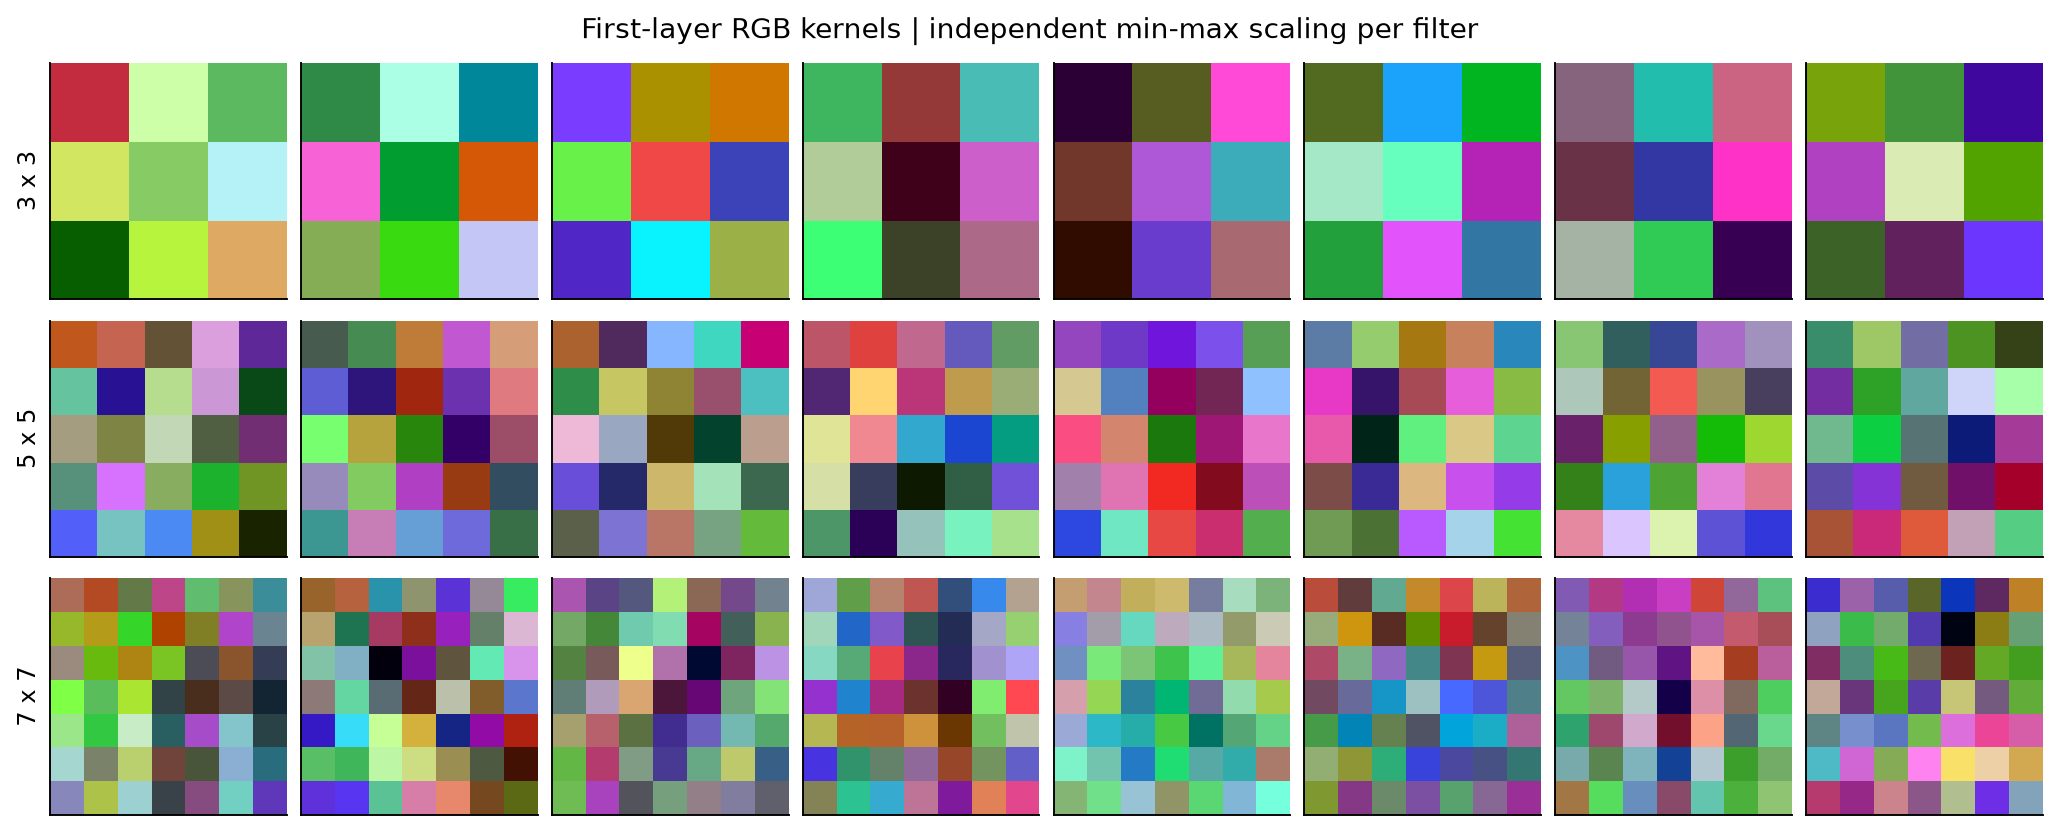

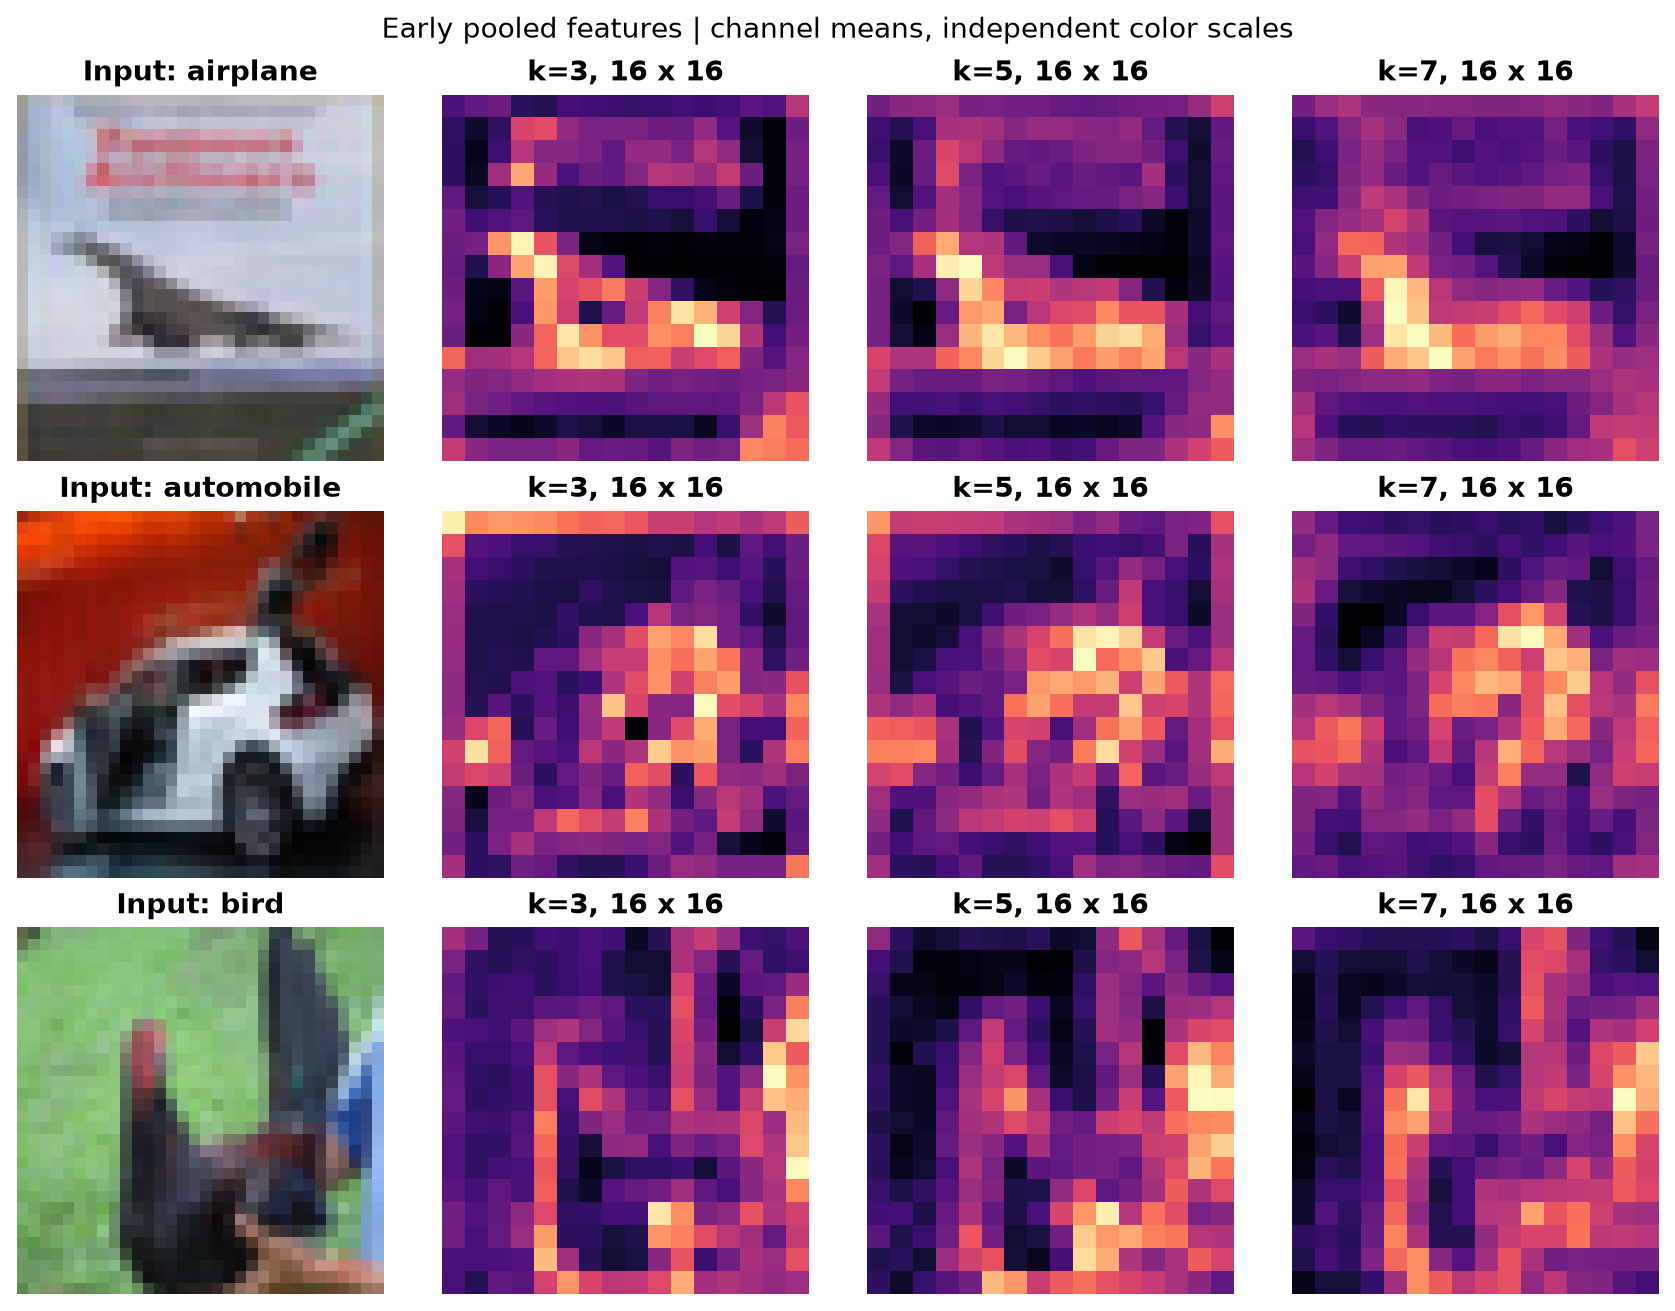

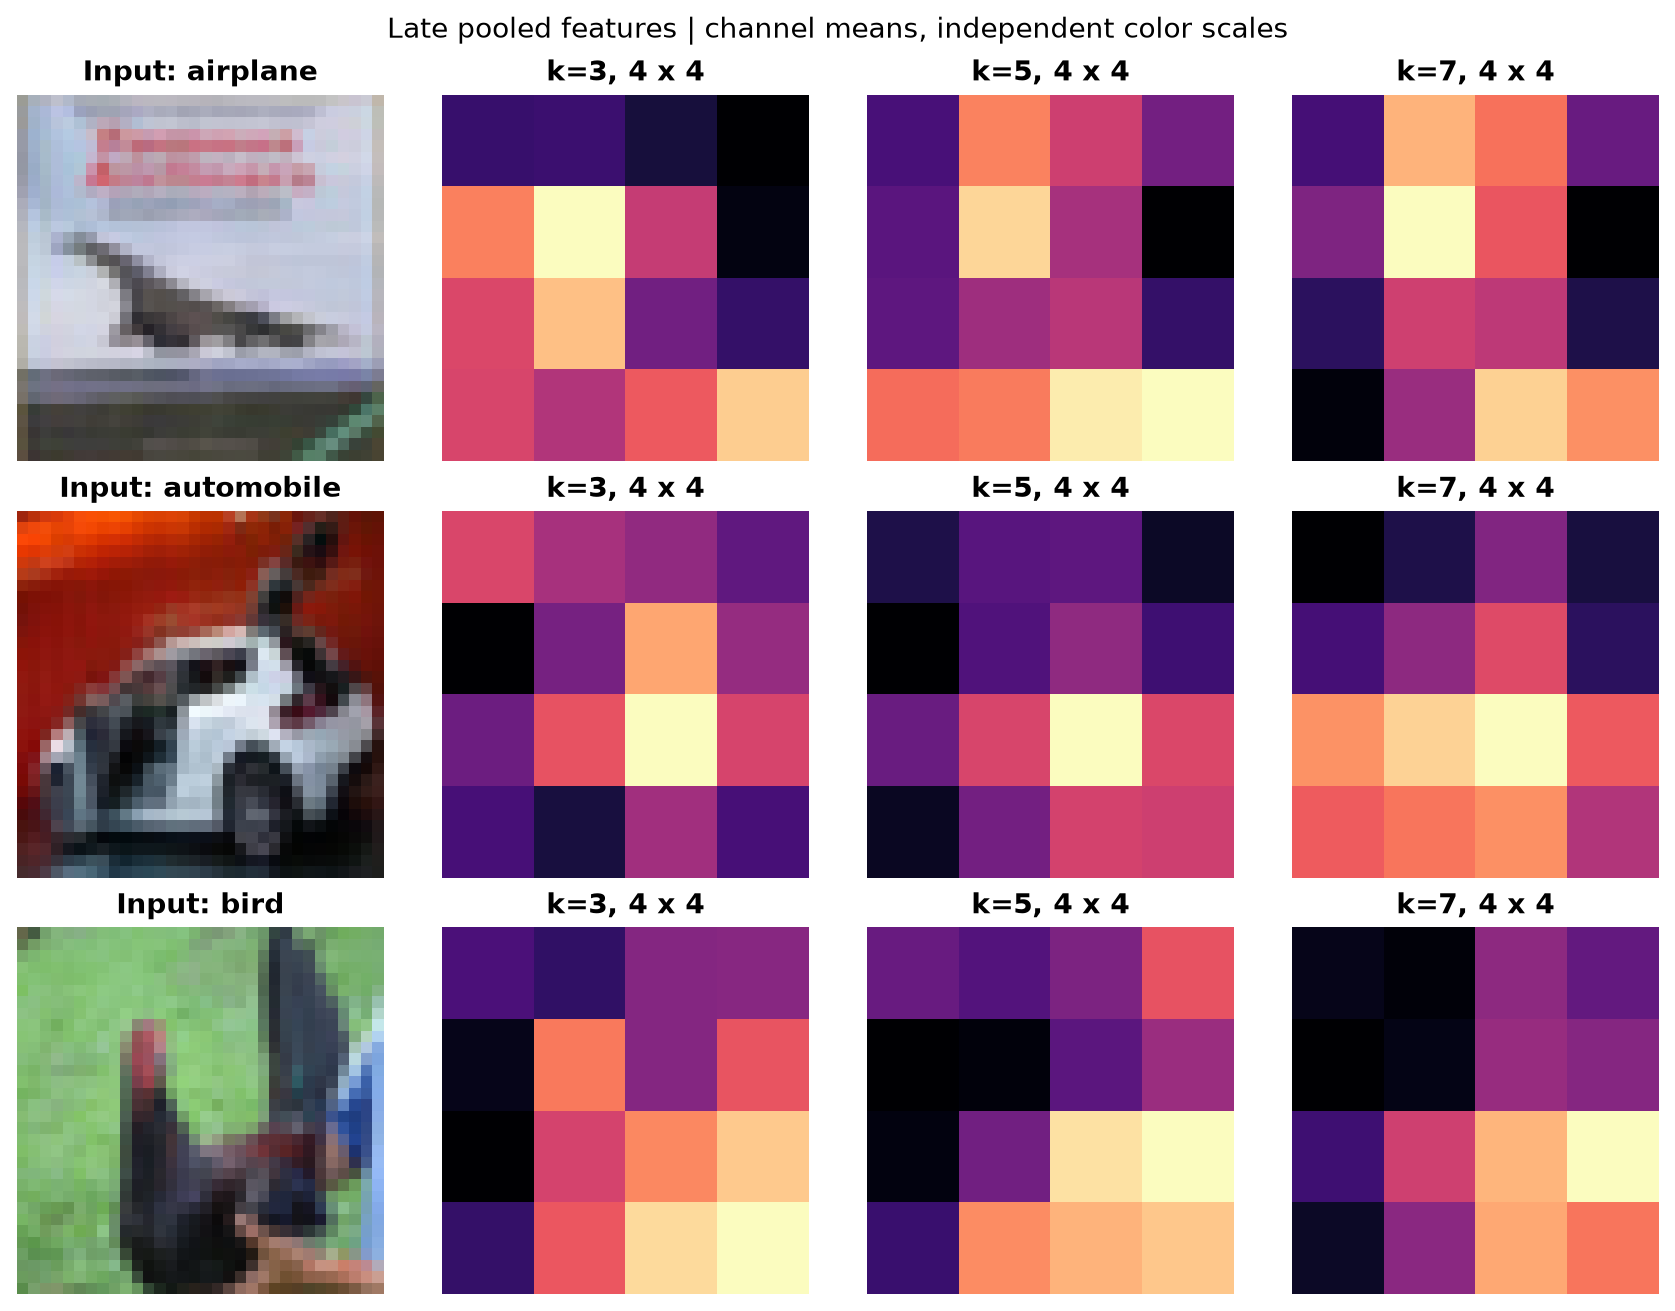

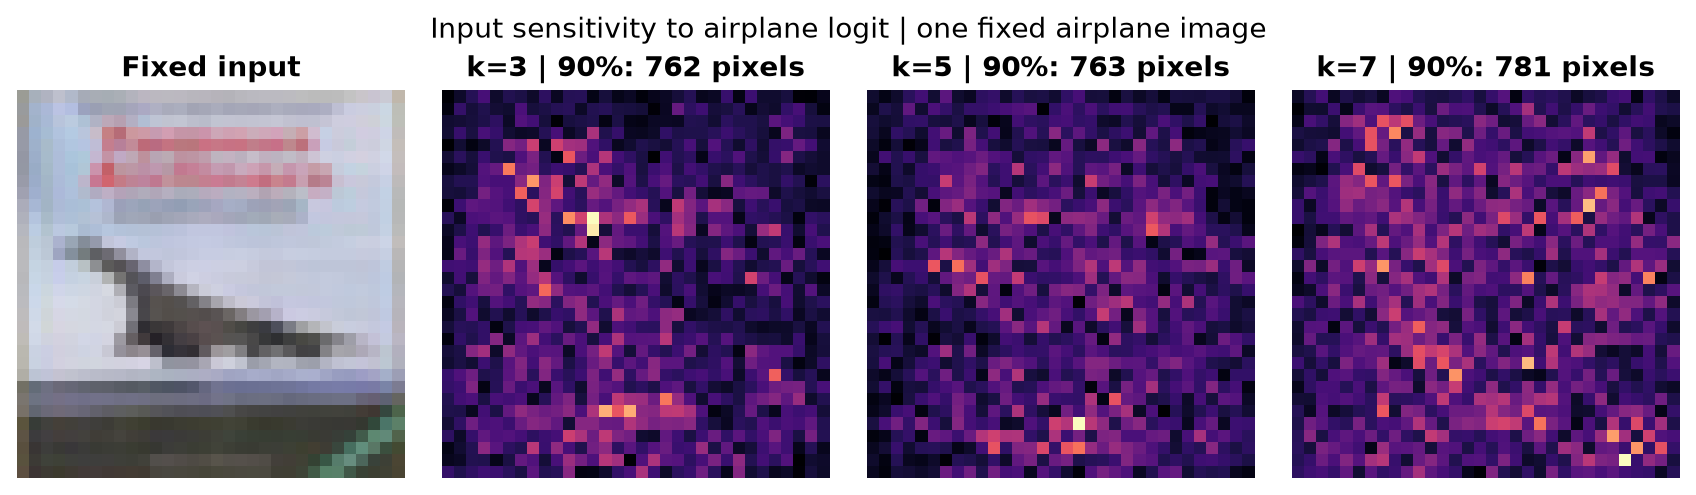

In [8]:
for name in ["kernel_weights", "features_early", "features_late", "input_sensitivity"]:
    display(Image(filename=str(ROOT / "figures" / f"{name}.png")))

## 误分类与缺陷

中心遮挡测试覆盖图像中央的 8×8 区域。Cutout 实验比较训练时加入随机遮挡后的准确率。

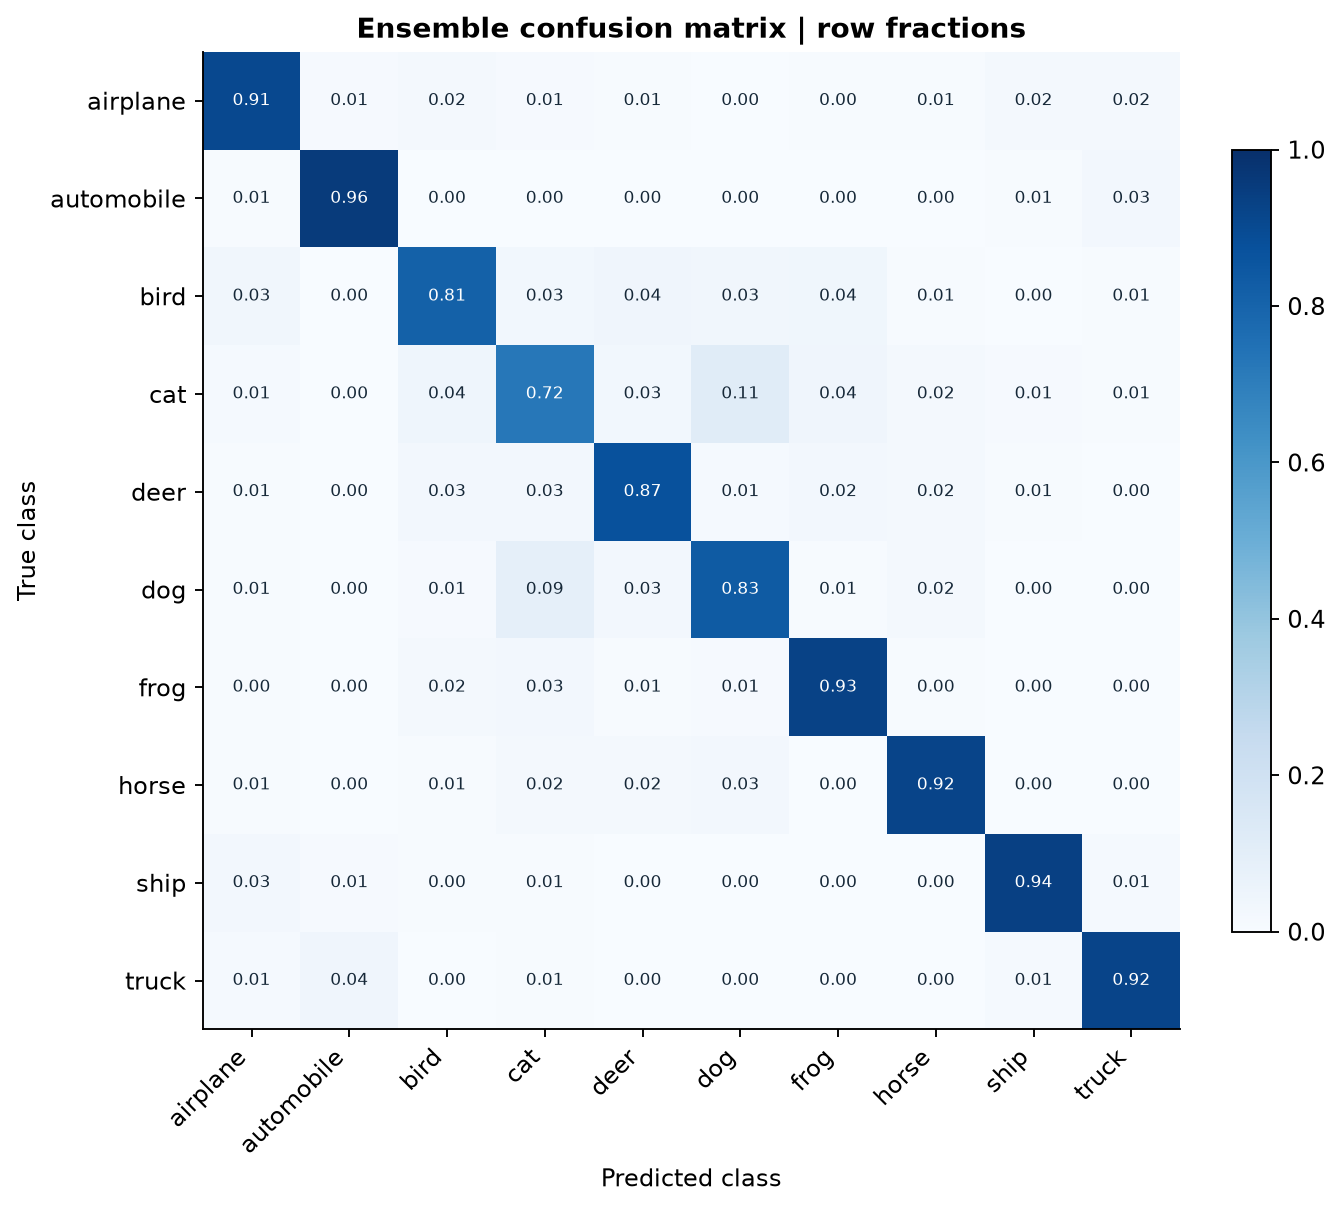

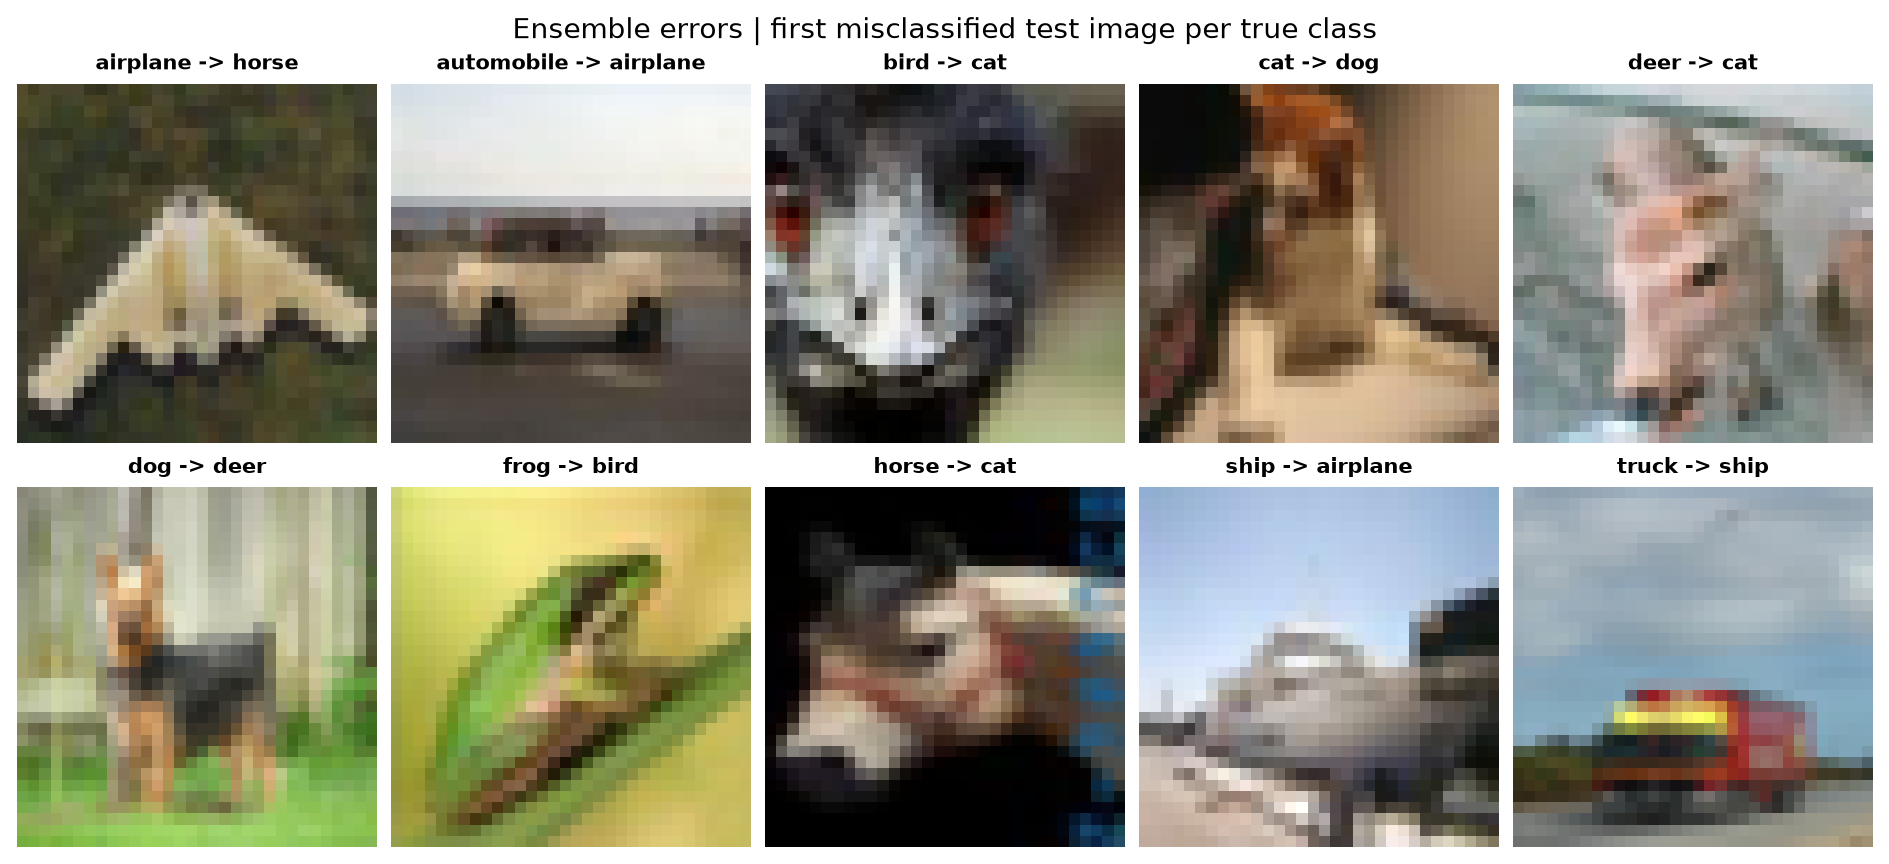

In [9]:
display(Image(filename=str(ROOT / "figures" / "confusion_matrix.png")))
display(Image(filename=str(ROOT / "figures" / "misclassifications.png")))

## 运行与检查

从本目录运行终端命令。`--resume` 跳过设置相同且训练完成的实验。

```bash
.venv/bin/python -m pytest -q
.venv/bin/python -m cifar10_lab.experiment --resume
.venv/bin/python -m cifar10_lab.report
.venv/bin/python -m cifar10_lab.verify
```

实验核验结果见 `results/verification.json`。